<div class="alert alert-info">
    
➡️ Before you start, make sure that you are familiar with the **[study guide](https://liu-nlp.ai/text-mining/logistics/)**, in particular the rules around **cheating and plagiarism**.

➡️ Make sure you fill in **all** cells that say **`YOUR CODE HERE`** or **YOUR ANSWER HERE**.  You normally shouldn't need to modify any of the other cells.

➡️ Make sure that you save the notebook **with the outputs from all cells visible,** as if you had run the notebook from top to bottom.

</div>

# L4: Clustering and Topic Modelling

<div class="alert alert-warning">

⚠️ Parts of this lab **require a GPU with 8GB+ VRAM.**  Unless you have such a GPU, you will likely not be able to run this part of the lab.  Remember that you can access the GPU-equipped lab rooms in B-huset – Åsgard, Egypten, Olympen – to work on this lab, preferably during the times we have booked one or more of these rooms for the course.

</div>


Text clustering groups documents in such a way that documents within a group are more &ldquo;similar&rdquo; to other documents in the cluster than to documents not in the cluster. The exact definition of what &ldquo;similar&rdquo; means in this context varies across applications and clustering algorithms.

In this lab you will experiment with both hard and soft clustering techniques. In the first part, you will represent documents both as sparse tf–idf vectors and as dense embeddings, visualise them with t-SNE, and cluster them with the $k$-means algorithm. In the second part, you will be using a topic model based on the Latent Dirichlet Allocation (LDA).

In [1]:
from liu_tm import check_solutions

## Dataset

The data for this lab comes from academic papers submitted to [arXiv](https://arxiv.org/).  We used the official [arXiv Dataset (version 309)](https://www.kaggle.com/datasets/Cornell-University/arxiv/data) to extract a sample of paper titles and abstracts from 2021–2026 across a small subset of categories (i.e., the scientific field of the paper).  The idea is that we can use clustering and topic modelling techniques on the abstracts, while using the archives and categories as a signal to compare our clusters and topics against. Let’s start by loading and inspecting the dataset:

In [2]:
import pandas as pd
import bz2
pd.set_option('display.max_colwidth', None)

with bz2.open('arxiv-sample.json.bz2') as source:
    df = pd.read_json(source)

df.head()

,id,date,archive,category,category_name,title,text
0,arXiv:2304.02838,2023-04-06,cs,cs.CR,Cryptography and Security,TBDetector:Transformer-Based Detector for Advanced Persistent Threats with Provenance Graph,"APT detection is difficult to detect due to the long-term latency, covert and slow multistage attack patterns of Advanced Persistent Threat (APT). To tackle these issues, we propose TBDetector, a transformer-based advanced persistent threat detection method for APT attack detection. Considering that provenance graphs provide rich historical information and have the powerful attacks historic correlation ability to identify anomalous activities, TBDetector employs provenance analysis for APT detection, which summarizes long-running system execution with space efficiency and utilizes transformer with self-attention based encoder-decoder to extract long-term contextual features of system states to detect slow-acting attacks. Furthermore, we further introduce anomaly scores to investigate the anomaly of different system states, where each state is calculated with an anomaly score corresponding to its similarity score and isolation score. To evaluate the effectiveness of the proposed method, we have conducted experiments on five public datasets, i.e., streamspot, cadets, shellshock, clearscope, and wget_baseline. Experimental results and comparisons with state-of-the-art methods have exhibited better performance of our proposed method."
1,arXiv:2606.20406,2026-06-18,stat,stat.ME,Methodology,Flexible modeling of bimodal distributions via skewed-$t$ mixtures,"We propose a mixture of location-scale skewed-$t$ distributions to fit bimodal, skewed and heavy-tailed data. In particular, the mixture is based on the skewed-$t$ distribution by Fern\'andez and Steel (1998), so that the model-building procedure can be easily extended to mixtures of other symmetric distributions. After studying the properties of the mixture, we develop a maximum likelihood estimation approach via the EM algorithm and a likelihood ratio test of the null hypothesis of no skewness in any given component. A simulation-based comparison to a recently proposed mixture of g-and-h distributions suggests that the performance of the proposed model is excellent, in terms of both estimation precision in well-specified setups and modeling capability in mis-specified frameworks. Fitting the model to the Standard & Poor's 500 distortion allows us to confirm the bimodality of its distribution, with the implication that the US stock market has historically been in bearish or bullish conditions, rather than near its fundamental value."
2,arXiv:2205.06320,2022-05-12,stat,stat.AP,Applications,Modelling spatially autocorrelated detection probabilities in spatial capture-recapture using random effects,"Spatial capture-recapture (SCR) models are now widely used for estimating density from repeated individual spatial encounters. SCR accounts for the inherent spatial autocorrelation in individual detections by modelling detection probabilities as a function of distance between the detectors and individual activity centres. However, additional spatial heterogeneity in detection probability may still creep in due to environmental or sampling characteristics. if unaccounted for, such variation can lead to pronounced bias in population size estimates. Using simulations, we describe and test three Bayesian SCR models that use generalized linear mixed models (GLMM) to account for latent heterogeneity in baseline detection probability across detectors using: independent random effects (RE), spatially autocorrelated random effects (SARE), and a two-group finite mixture model (FM). Overall, SARE provided the least biased population size estimates (median RB: -9 -- 6%). When spatial autocorrelation was high, SARE also performed best at predicting the spatial pattern of heterogeneity in detection probability. At intermediate levels of autocorrelation, spatially-explicit estimates of detection 

Let’s check which categories are represented in this dataset and how many papers each one has:

In [3]:
df.value_counts(["archive", "category", "category_name"]).sort_index().reset_index()

,archive,category,category_name,count
0,astro-ph,astro-ph.EP,Earth and Planetary Astrophysics,1000
1,astro-ph,astro-ph.GA,Astrophysics of Galaxies,1000
2,cs,cs.CL,Computation and Language,1000
3,cs,cs.CR,Cryptography and Security,1000
4,cs,cs.CV,Computer Vision and Pattern Recognition,1000
5,econ,econ.EM,Econometrics,1000
6,econ,econ.GN,General Economics,1000
7,q-bio,q-bio.NC,Neurons and Cognition,1000
8,q-bio,q-bio.PE,Populations and Evolution,1000
9,stat,stat.AP,Applications,1000


You can see that `archive` is a broader category corresponding to one of five scientific fields:

- **astro-ph**: Astrophysics
- **cs**: Computer Science
- **econ**: Economics
- **q-bio**: Quantitative Biology
- **stat**: Statistics

Within each of these “archives”, there are more specific `category` values that are explained in the column `category_name`.  Keep in mind that this is only a small sample of arXiv’s papers, with only a selected subset of categories being represented here.

## Problem 1: Document representations

To cluster documents, we first need to represent them as vectors.  In Lab&nbsp;1, you have already seen two ways of doing this: *sparse tf–idf vectors* and *dense embeddings* from a neural embedding model.  In this lab, we will use both of them and compare how well they work for clustering.

### TF–IDF vectors

We start by performing tf–idf vectorization of the abstracts.  You should already know how this works from Lab&nbsp;1.  This time, we just want to add one step: **filtering out stop words**.  The idea is that for clustering a text by topic, common stop words (like _the_, _and_, _of_, ...) are unlikely to contribute something meaningful to this task.

<div class="alert alert-info">

Complete the following cell to **perform tf–idf vectorization with stop word filtering**!  While there are different ways to filter for stop words, [TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html) comes with a handy initialization option that you can use for this.

After running the following cell:
- `vectorizer` should contain the vectorizer fitted on `df['text']`
- `tfidf` should contain the vectorized `df['text']`

</div>

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(stop_words='english')
tfidf = vectorizer.fit_transform(df['text'])

### Dense embeddings

Next, we compute dense document embeddings with [EmbeddingGemma2](https://developers.googleblog.com/embeddinggemma-2-the-developer-guide/), the same model that you used in Lab&nbsp;1.  The following cells load the model, just like in Lab&nbsp;1:

In [5]:
from pathlib import Path
from liu_tm.torch import check_gpu

check_gpu()
# This part checks if we’re on the lab computers, and loads the model from there
model_name = Path("/courses/TDDE16/models/google/embeddinggemma-2")
if not model_name.exists():
    model_name = "google/embeddinggemma-2"

In [6]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer(
    model_name,
    # Text only (270M parameters)
    config_kwargs={"vision_config": None, "audio_config": None},
)

W1105 15:01:54.615000 15453 course-materials/.venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/413 [00:00<?, ?it/s]

In Lab&nbsp;1, you used the `"SearchQuery"` and `"Document"` prompts for search.  EmbeddingGemma2 has been trained with different prompts for different tasks, and the prompt that is prepended to the text changes the embedding that you get.  You can see all prompts that the model supports by running the following cell:

In [ ]:
model.prompts

We can see that EmbeddingGemma2 has a separate prompt for `"Clustering"`, so we are going to use that.  Other than that, computing the embeddings works the same way as we have seen in Lab&nbsp;1.

<div class="alert alert-info">

Complete the following cell to **compute embeddings for all abstracts in the dataset**, using the “clustering” prompt this time.

After running the following cell:
- `embeddings` should be a NumPy array containing one embedding vector for each row in `df`

</div>

In [9]:
embeddings = model.encode(
    df['text'].tolist(),
    prompt_name="Clustering",
    batch_size=32,
    show_progress_bar=True,
)

Batches:   0%|          | 0/344 [00:00<?, ?it/s]

#### 🤞 Test your code

The following cell sanity-checks your embeddings:

In [10]:
"""Check that there is one embedding per abstract."""

import numpy as np
print(f"    tf–idf array shape: {tfidf.shape}")
print(f"dense embeddings shape: {embeddings.shape}")

with check_solutions() as check:
    check.equals(tfidf.shape[0], len(df))
    check(tfidf.shape[1] > 40000)
    check("and" not in vectorizer.vocabulary_, "Stop words should have been filtered out")
    check.equals(embeddings.shape, (len(df), 768))

    tf–idf array shape: (11000, 42814)
dense embeddings shape: (11000, 768)


## Problem 2: Visualising document representations

Both of our representations are high-dimensional: the tf–idf vectors have one dimension per word in the vocabulary, while the embeddings have 768 dimensions.  To get a feeling for how the documents are distributed in these spaces, we can use a _dimensionality reduction_ technique like [t-SNE](https://scikit-learn.org/stable/modules/manifold.html#t-sne) to map them into two dimensions and plot them.

t-SNE can be slow on large datasets and on very high-dimensional vectors, so we will simplify the visualization in two ways:

1. We will use [TruncatedSVD](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html) to reduce the dimensionality to 50 before feeding the vectors into t-SNE.  This is recommended in the [documention for the TSNE class](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html) itself.
2. We will only visualise a _random sample_ of 3,000 abstracts.  The following cell creates an array `sample` with the row indices of that sample:

In [11]:
sample = df.sample(3000, random_state=42).index.to_numpy()

<div class="alert alert-info">

**Complete the function below** so that it:

1. maps the given vectors into a two-dimensional space with t-SNE,
2. plots the resulting points as a scatterplot, and
3. uses the given labels for the _colour_ of each point in the plot.

We have already instantiated [TruncatedSVD](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html) and [TSNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html) classes that you can use.  You can use either plain Matplotlib or [Seaborn](https://seaborn.pydata.org/) for the plot.

</div>

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE

sns.set_theme(style="white")

def plot_tsne(vectors, labels, perplexity=30.0, max_iter=1000, title=None):
    """Compute and plot a t-SNE reduction of the given vectors.

    Arguments:
        vectors: The vectors to plot; can be sparse or dense.
        labels: A list of labels, used for colouring the points; must have the
            same length as `vectors`.
        perplexity (float): A hyperparameter of the t-SNE algorithm; recommended values
            are between 5 and 50, and can result in significantly different results.
        max_iter (int): A hyperparameter of the t-SNE algorithm, controlling the maximum
            number of iterations of the optimization algorithm.
        title (str): An optional title for the plot.

    Returns:
        Nothing, but shows the plot.
    """
    svd = TruncatedSVD(n_components=50)
    tsne = TSNE(perplexity=perplexity, max_iter=max_iter)
    vectors_svd = svd.fit_transform(vectors)
    vectors_tsne = tsne.fit_transform(vectors_svd)
    sns.scatterplot(x=vectors_tsne[:, 0], y=vectors_tsne[:, 1], hue=labels)
    plt.title(title)
    plt.show()

#### 🤞 Test your code

If your implementation is correct, the following cell should produce two plots of the same sample of abstracts, coloured by their category – one for the tf–idf vectors and one for the dense embeddings:

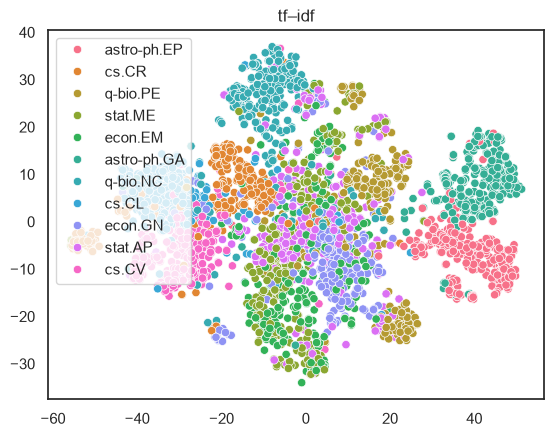

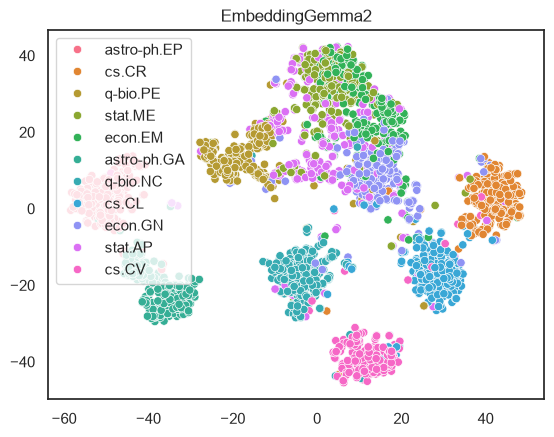

In [19]:
categories = df["category"].to_numpy()

perp = 50.0
plot_tsne(tfidf[sample], categories[sample], perplexity=perp, title="tf–idf")
plot_tsne(embeddings[sample], categories[sample], perplexity=perp, title="EmbeddingGemma2")

Afterwards, **re-run the visualisation** a few times with different values for the `perplexity` parameter, and observe if and how the resulting visualisation changes.  You can also try colouring the points by `archive` instead of `category`.  Take a moment to consider how you would interpret the results.

## Problem 3: K-means clustering

Your next task is to cluster both representations using $k$-means clustering and to evaluate the resulting clusters.

<div class="alert alert-info">

**Write a function to cluster the vectorized data.**  For this, you can use scikit-learn’s [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html) class, which has several parameters that you can tweak, the most important one being the _number of clusters_.  Your function should therefore take the number of clusters as an argument; you can leave all other parameters at their defaults.

</div>

In [20]:
from sklearn.cluster import KMeans

def fit_kmeans(data, n_clusters):
    """Fit a k-means classifier to some data.

    Arguments:
        data: The vectorized data to train the classifier on.
        n_clusters (int): The number of clusters.

    Returns:
        The trained k-means classifier.
    """
    kmeans = KMeans(n_clusters=n_clusters)
    return kmeans.fit(data)

#### 🤞 Test your code

The following cell clusters both representations into $k=11$ clusters – the number of categories in our dataset – and plots them with our t-SNE implementation from Problem&nbsp;2.  Note that sizes may vary considerably between clusters and among different random seeds, so there is no single “correct” output here!  Re-run the cell a couple of times to observe how the plots change, and also compare them to the plots from Problem&nbsp;2.

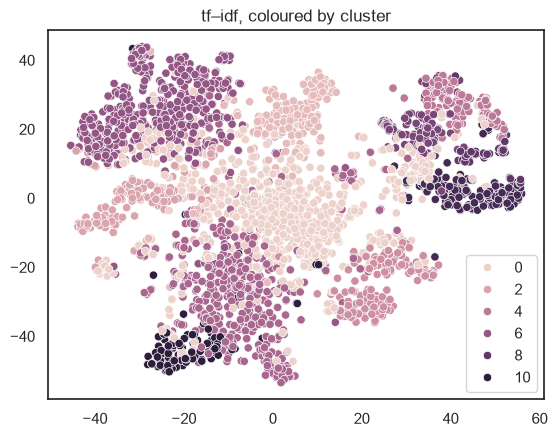

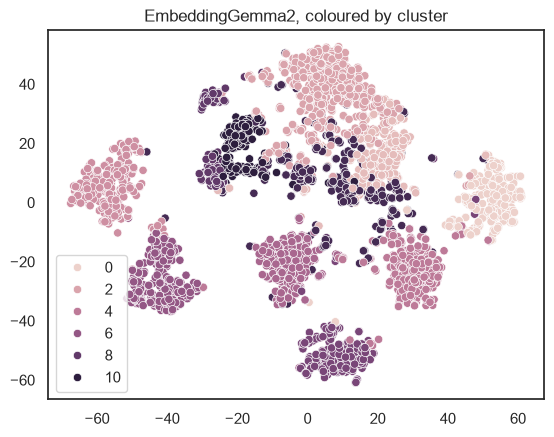

In [21]:
kmeans_tfidf = fit_kmeans(tfidf, 11)
plot_tsne(tfidf[sample], kmeans_tfidf.labels_[sample], title="tf–idf, coloured by cluster")

kmeans_dense = fit_kmeans(embeddings, 11)
plot_tsne(embeddings[sample], kmeans_dense.labels_[sample], title="EmbeddingGemma2, coloured by cluster")

### Evaluating clustering performance

In some scenarios, you have gold-standard class labels available for at least a subset of your documents.  In our case, we can use the arXiv `archive` or `category` columns as class labels.  This means we’re making the assumption that a “good” clustering should put texts into the same cluster _if and only if_ they belong to the same archive (or category).

If we have such class labels, we can compute a variety of performance measures to see how well our $k$-means clustering resembles the given class labels.  Here, we will consider three of these measures: the **Rand index (RI)**; the **adjusted Rand index (ARI)** which has been corrected for chance; and the **V-measure**.  For all of them (and more), we can make use of [implementations by scikit-learn](https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation).

<div class="alert alert-info">

Your task is to compare the performance of $k$-means clusterings with $k = 2, \ldots, 15$ clusters, for _both representations_ (tf–idf and dense embeddings), and evaluate each clustering against _both sets of gold-standard labels_ (`archive` and `category`).

**Visualise your results as line plots**, where

- there is one subplot for each set of gold-standard labels (`archive` and `category`)
- the $x$-axis corresponds to $k$
- the $y$-axis corresponds to the score of the evaluation measure
- each evaluation measure (RI, ARI, V) is shown by a differently-coloured line
- each representation (tf–idf, dense) is shown by a differently-styled line

</div>

_Hint:_ This is easiest if you collect all results in a DataFrame in “long” format, where each row represents a combination of representation, $k$, gold-standard labels, and evaluation measure, for example:

|       | representation | k | gold    | measure | score |
|-------|:---------------|:-:|:--------|:--------|------:|
| **0** | tf-idf         | 2 | archive | RI      | 0.611 |

You can then use [seaborn.relplot](https://seaborn.pydata.org/generated/seaborn.relplot.html) to create the whole figure with a single function call.

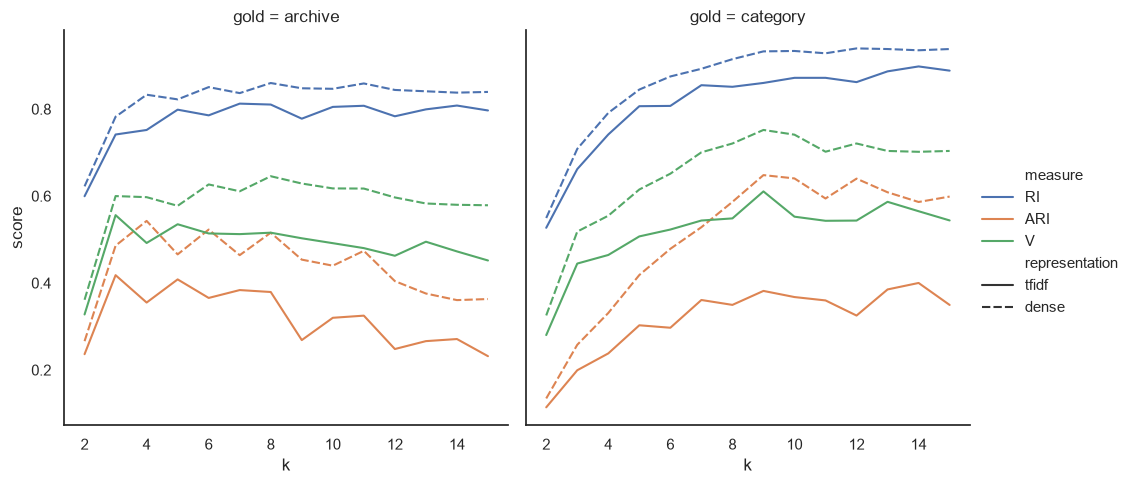

In [23]:
from sklearn.metrics import rand_score, adjusted_rand_score, v_measure_score

reps = {"tfidf": tfidf, "dense": embeddings}
gt_labels = {"archive": df["archive"], "category": df["category"]}
measures = {"RI": rand_score, "ARI": adjusted_rand_score, "V": v_measure_score}

res = []
for representation, data in reps.items():
    for k in range(2, 16):
        cluster_labels = fit_kmeans(data, k).labels_
        for gold, lab in gt_labels.items():
            for measure, score_function in measures.items():
                res.append({
                    "representation": representation,
                    "k": k,
                    "gold": gold,
                    "measure": measure,
                    "score": score_function(lab, cluster_labels),
                })

sns.relplot(
    data=pd.DataFrame(res),
    kind="line",
    x="k",
    y="score",
    hue="measure",
    style="representation",
    col="gold",
)

Remember that you may get different clusters each time you run the $k$-means algorithm, so re-run your solution above a few times to see how the results change.  Take a moment to think how you would interpret these results.

## Problem 4: Describing clusters

Another way to analyse the results of a clustering algorithm is to **generate a “summary”** for each cluster, to try to see if it appears to group meaningful terms or documents.  One way to do this is to extract the $n$ highest-weighted terms from the centroid of each cluster.  For tf–idf vectors, this is straightforward, since each dimension of the centroid corresponds to a term in the vocabulary.  For dense embeddings, however, the individual dimensions have no meaning that we can interpret.

We can work around this by **combining both representations**: we take the clusters (i.e., the cluster labels) from one representation, but compute the centroids from the tf–idf vectors of the documents in each cluster.  For clusters that were computed on the tf–idf vectors, this gives exactly the same centroids that $k$-means computed, since a $k$-means centroid is the mean of the vectors in its cluster.  For clusters that were computed on the dense embeddings, it gives us a way to describe them in words.

(_Side note:_ This idea of clustering dense embeddings and describing the clusters with a variant of tf–idf is the basis of [BERTopic](https://maartengr.github.io/BERTopic/), a popular embedding-based alternative to topic models like LDA.)

<div class="alert alert-info">

Complete the function below to **compute cluster summaries** as described above.

</div>

In [27]:
def compute_cluster_summaries(cluster_labels, tfidf, vectorizer, top_n):
    """Compute the top_n highest-weighted terms from the tf–idf centroid of each cluster.

    Arguments:
        cluster_labels: The cluster label for each document, e.g. `kmeans.labels_`.
        tfidf: The tf–idf vectors of the documents.
        vectorizer: The fitted vectorizer; needed to obtain the actual terms
                    belonging to the dimensions of the tf–idf vectors.
        top_n: The number of terms to return for each cluster.

    Returns:
        A list of length k, where k is the number of clusters. Each item in the list
        should be a list of length `top_n` with the highest-weighted terms from that
        cluster.  Example:
          [["first", "foo", ...], ["second", "bar", ...], ["third", "baz", ...]]
    """
    cluster_labels = np.asarray(cluster_labels)
    terms = vectorizer.get_feature_names_out()
    summaries = []
    for cluster in range(max(cluster_labels) + 1):
        centroid = tfidf[cluster_labels == cluster].mean(axis=0).A1
        top_indices = centroid.argsort()[-top_n:][::-1]
        summaries.append(terms[top_indices].tolist())
    return summaries

#### 🤞 Test your code

The following cell tests your function on a toy example:

In [28]:
"""Check compute_cluster_summaries() on a toy example."""

toy_vectorizer = TfidfVectorizer()
toy_tfidf = toy_vectorizer.fit_transform(["apple banana", "apple cherry", "dog cat", "dog mouse"])
toy_summaries = compute_cluster_summaries([0, 0, 1, 1], toy_tfidf, toy_vectorizer, 1)

with check_solutions() as check:
    check.equals(len(toy_summaries), 2, "There should be one summary per cluster")
    check.equals(toy_summaries, [["apple"], ["dog"]], "The top term should be 'apple' for cluster 0 and 'dog' for cluster 1")

The following helper function prints the summaries next to the size of each cluster and its most frequent category:

In [29]:
def print_cluster_summaries(cluster_labels, summaries):
    for cluster, terms in enumerate(summaries):
        members = df["category"][cluster_labels == cluster]
        top_category = members.value_counts().idxmax()
        print(f"Cluster {cluster:2d} ({len(members):4d} docs, mostly {top_category:>11s}): {', '.join(terms)}")

In [30]:
print("tf–idf clusters:")
print_cluster_summaries(kmeans_tfidf.labels_, compute_cluster_summaries(kmeans_tfidf.labels_, tfidf, vectorizer, 10))

print("\nEmbeddingGemma2 clusters:")
print_cluster_summaries(kmeans_dense.labels_, compute_cluster_summaries(kmeans_dense.labels_, tfidf, vectorizer, 10))

tf–idf clusters:
Cluster  0 (3203 docs, mostly     econ.GN): data, model, economic, using, study, based, results, time, paper, analysis
Cluster  1 ( 737 docs, mostly    q-bio.NC): brain, neural, networks, network, neurons, activity, connectivity, learning, neuronal, functional
Cluster  2 ( 681 docs, mostly       cs.CR): privacy, security, attacks, attack, data, detection, malware, learning, iot, based
Cluster  3 ( 733 docs, mostly    q-bio.PE): species, population, dynamics, model, disease, covid, epidemic, 19, infection, transmission
Cluster  4 ( 486 docs, mostly astro-ph.GA): galaxies, mass, stellar, galaxy, star, stars, formation, clusters, cluster, gas
Cluster  5 (1747 docs, mostly     stat.ME): data, model, models, method, estimation, proposed, methods, bayesian, regression, estimator
Cluster  6 (1868 docs, mostly       cs.CV): language, models, image, model, training, tasks, text, llms, task, performance
Cluster  7 ( 363 docs, mostly astro-ph.GA): emission, radio, gas, agn, line,

Once you have computed the cluster summaries, take a minute to reflect on their quality.  Is it clear what the abstracts in a given cluster are about?  Do the summaries contain any unexpected terms?

## Problem 5: Topic modelling

Unlike $k$-means, which assigns each document to exactly one cluster (i.e., a hard clustering algorithm), a **topic model** like LDA represents each document as a _mixture_ of topics, and each topic as a distribution over words.  In this part of the lab, we will train such a model and see how it compares with the hard clustering from above.  For this, we will be using [spaCy](https://spacy.io/) and the [gensim](https://radimrehurek.com/gensim/) topic modelling library.  We will use the same dataset of arXiv abstracts as before.

Take a few minutes to think about what topics you would expect in this dataset, and how they might relate to the arXiv categories.

### Preparing the data

<div class="alert alert-info">

Complete the function below to **preprocess the abstracts** using spaCy as follows:

- Lowercase all tokens.
- Filter out stop words, non-alphabetic tokens, and tokens less than 3 characters in length.

Return the results as a nested list: a list of documents where each document is represented by a list of its tokens (after preprocessing).

</div>

_Note:_ Since we only need tokenization and the stop word list for this, we use a _blank_ spaCy pipeline that only contains the tokenizer, which is much faster than a full pipeline like `en_core_web_md`.  To process many texts efficiently, use [nlp.pipe()](https://spacy.io/api/language#pipe).

In [ ]:
import spacy

# A blank English pipeline only contains the tokenizer, which is all we need here
nlp = spacy.blank("en")

In [32]:
def preprocess_documents(texts):
    """Preprocess all documents in the given list of texts.

    The preprocessing must lowercase all tokens, and filter out stop words,
    non-alphabetic tokens, and tokens less than 3 characters in length.

    Arguments:
        texts: A list of texts, e.g. `df["text"]`.

    Returns:
        A list of length n, where n is the number of texts.
        Each item in the list should be a list of tokens in the given
        document, after preprocessing.
    """
    documents = []
    for doc in nlp.pipe(texts):
        tokens = [
            token.lower_
            for token in doc
            if not token.is_stop and token.is_alpha and len(token) >= 3
        ]
        documents.append(tokens)
    return documents

#### 🤞 Test your code

Test your preprocessing by running the following cell.  It will output the tokens (after preprocessing) for an example document, and compare the first ten tokens of another document against the expected output.

In [33]:
"""Check the preprocessed documents."""

documents = preprocess_documents(df["text"])
print(f"Document 111 before preprocessing:\n{df["text"].iloc[111]}\n")
print(f"Document 111 after preprocessing:\n{' '.join(documents[111])}\n")

with check_solutions() as check:
    check.equals(len(documents), len(df), "There should be one list of tokens per abstract")
    check.equals(
        " ".join(documents[42][:10]),
        "calcium deficiency high yielding bovines calving causes milk fever leads",
        "The first ten tokens of document 42 are not as expected",
    )

Document 111 before preprocessing:
Ultra-cool dwarf stars are abundant, long-lived, and uniquely suited to enable the atmospheric study of transiting terrestrial companions with JWST. Amongst them, the most prominent is the M8.5V star TRAPPIST-1 and its seven planets. While JWST Cycle 1 observations have started to yield preliminary insights into the planets, they have also revealed that their atmospheric exploration requires a better understanding of their host star. Here, we propose a roadmap to characterize the TRAPPIST-1 system -- and others like it -- in an efficient and robust manner. We notably recommend that -- although more challenging to schedule -- multi-transit windows be prioritized to mitigate the effects of stellar activity and gather up to twice more transits per JWST hour spent. We conclude that, for such systems, planets cannot be studied in isolation by small programs, but rather need large-scale, jointly space- and ground-based initiatives to fully exploit the capab

### Training LDA

Now that we have the list of documents, we can use gensim to train an LDA model on them.  Gensim works a bit differently from scikit-learn and has its own interfaces, so we provide the implementation for this below.  Take a moment to read through it: gensim needs a _dictionary_ that maps each word to an integer ID, and a _corpus_ that represents each document as a bag of words.  (If you want to learn more, the gensim documentation has a [tutorial on LDA](https://radimrehurek.com/gensim/auto_examples/tutorials/run_lda.html).)

The function also shows a progress bar during training, and has a `monitor` option that we will come back to in Problem&nbsp;6.

In [34]:
from gensim.corpora.dictionary import Dictionary
from gensim.models import LdaModel
from gensim.models.callbacks import Metric, PerplexityMetric
from rich.progress import Progress


class ProgressBarCallback(Metric):
    """Not a real metric: only advances a progress bar after each training pass."""

    def __init__(self, progress, task):
        self.progress = progress
        self.task = task
        self.logger = None
        self.title = "Progress"

    def get_value(self, **kwargs):
        # Refresh explicitly, as Jupyter otherwise doesn't always show the final state
        self.progress.update(self.task, advance=1, refresh=True)


def train_lda_model(documents, num_topics, passes=1, monitor=False):
    """Create and train an LDA model.

    Arguments:
        documents: The preprocessed documents, as produced by `preprocess_documents()`.
        num_topics: The number of topics to generate.
        passes: The number of training passes.
        monitor: Whether to compute the perplexity after each training pass;
                 you will need this in Problem 6.

    Returns:
        The trained LDA model.
    """
    # Map each word to an integer ID, and represent each document as a
    # bag of words, i.e. a list of (word ID, count) pairs
    dictionary = Dictionary(documents)
    corpus = [dictionary.doc2bow(doc) for doc in documents]

    with Progress() as progress:
        task = progress.add_task("Training LDA", total=passes)
        callbacks = [ProgressBarCallback(progress, task)]
        if monitor:
            # Computes the perplexity on the training corpus after each pass,
            # which is then stored in `model.metrics["Perplexity"]`
            callbacks.insert(0, PerplexityMetric(corpus=corpus))

        model = LdaModel(
            corpus=corpus,
            id2word=dictionary,
            num_topics=num_topics,
            passes=passes,
            callbacks=callbacks,
        )

    # Remove the (empty) values of our progress bar "metric"
    model.metrics.pop("Progress")
    return model

Run the following cell to train an LDA model with 11 topics and print the topics:

In [35]:
lda = train_lda_model(documents, 11)
lda.print_topics()

Output()

[(0,
  '0.009*"brain" + 0.007*"data" + 0.006*"network" + 0.006*"privacy" + 0.005*"framework" + 0.005*"based" + 0.005*"security" + 0.005*"model" + 0.005*"systems" + 0.004*"analysis"'),
 (1,
  '0.016*"models" + 0.012*"language" + 0.012*"model" + 0.007*"performance" + 0.006*"tasks" + 0.006*"large" + 0.006*"data" + 0.006*"llms" + 0.006*"based" + 0.005*"training"'),
 (2,
  '0.012*"data" + 0.008*"models" + 0.007*"model" + 0.006*"ice" + 0.005*"space" + 0.004*"backdoor" + 0.004*"water" + 0.003*"surface" + 0.003*"based" + 0.003*"time"'),
 (3,
  '0.012*"neural" + 0.008*"model" + 0.008*"learning" + 0.007*"network" + 0.006*"networks" + 0.006*"features" + 0.005*"visual" + 0.005*"information" + 0.005*"brain" + 0.004*"detection"'),
 (4,
  '0.009*"based" + 0.007*"model" + 0.007*"data" + 0.007*"methods" + 0.006*"learning" + 0.006*"models" + 0.006*"method" + 0.005*"image" + 0.004*"information" + 0.004*"paper"'),
 (5,
  '0.017*"attacks" + 0.012*"data" + 0.012*"attack" + 0.009*"security" + 0.008*"detectio

Inspect the topics. Can you &lsquo;label&rsquo; each topic with a short description of what it is about? Do the topics match your expectations?  How do they relate to the arXiv categories, and to the cluster summaries from Problem&nbsp;4?

## Problem 6: Monitor a topic model for convergence

When learning an LDA model, it is important to make sure that the training algorithm has converged to a stable posterior distribution. One way to do so is to plot, after each training epoch (or &lsquo;pass&rsquo;, in gensim parlance), how well the model fits the training data.  A common measure for this is **perplexity**, which is directly related to the log likelihood of the data: if $\ell$ is the per-word (lower bound on the) log likelihood, then the perplexity is $2^{-\ell}$.  This means that _lower_ perplexity corresponds to a _better_ fit.

The `train_lda_model()` function from Problem&nbsp;5 can compute the perplexity for us: when called with `monitor=True`, it uses a gensim [callback](https://radimrehurek.com/gensim/models/callbacks.html) to compute the perplexity on the training corpus after each pass.  The trained model then has an attribute `metrics`, which is a dictionary containing a list of perplexity values (one per pass) under the key `"Perplexity"`.

For example, the following cell trains a model for a single pass with monitoring enabled, and prints the resulting list of perplexity values (which only has a single entry here):

In [36]:
lda = train_lda_model(documents, 11, passes=1, monitor=True)
print([float(p) for p in lda.metrics["Perplexity"]])

Output()

[442.97599626596923]


### Plotting perplexity

<div class="alert alert-info">

**Re-train your LDA model for 30&nbsp;passes** with monitoring enabled.  Afterwards, **create a plot** of the perplexity after each pass.

_Note:_ Computing the perplexity after each pass makes training slower, so this will take several minutes.

</div>

Output()

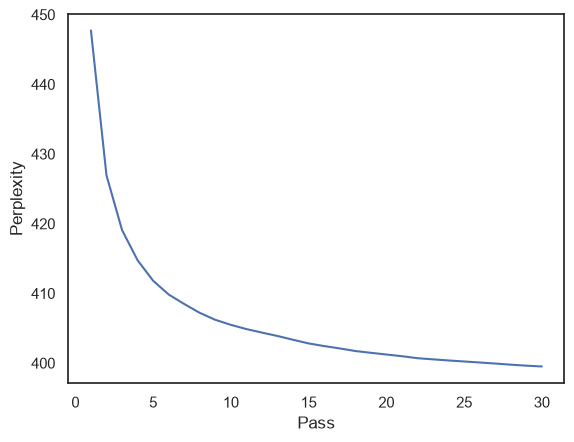

In [37]:
lda = train_lda_model(documents, 11, passes=30, monitor=True)
perplexities = [float(perplexity) for perplexity in lda.metrics["Perplexity"]]

plt.plot(range(1, len(perplexities) + 1), perplexities)
plt.xlabel("Pass")
plt.ylabel("Perplexity")
plt.show()

### Interpreting the plot

<div class="alert alert-info">

Based on the plot above, what would be a reasonable choice for the number of passes?  **Retrain your LDA model with that number** (you don’t need monitoring for this) and re-inspect the topics it finds.

</div>

In [38]:
lda = train_lda_model(documents, 11, passes=15)
lda.print_topics()

Output()

[(0,
  '0.020*"neural" + 0.013*"network" + 0.012*"networks" + 0.011*"activity" + 0.009*"dynamics" + 0.008*"brain" + 0.008*"neurons" + 0.007*"model" + 0.007*"information" + 0.006*"systems"'),
 (1,
  '0.010*"economic" + 0.007*"study" + 0.007*"market" + 0.007*"policy" + 0.006*"data" + 0.006*"impact" + 0.006*"risk" + 0.005*"effects" + 0.005*"level" + 0.005*"results"'),
 (2,
  '0.028*"brain" + 0.017*"clinical" + 0.009*"functional" + 0.008*"patients" + 0.008*"cognitive" + 0.008*"quantum" + 0.008*"eeg" + 0.007*"patient" + 0.007*"study" + 0.007*"analysis"'),
 (3,
  '0.014*"data" + 0.011*"security" + 0.010*"attacks" + 0.010*"privacy" + 0.008*"based" + 0.007*"detection" + 0.007*"systems" + 0.007*"system" + 0.007*"attack" + 0.006*"paper"'),
 (4,
  '0.017*"model" + 0.011*"population" + 0.008*"dynamics" + 0.008*"species" + 0.006*"models" + 0.005*"evolution" + 0.005*"number" + 0.004*"time" + 0.004*"results" + 0.004*"disease"'),
 (5,
  '0.016*"model" + 0.014*"models" + 0.013*"learning" + 0.010*"perfo

## Individual reflection

<div class="alert alert-warning">

**After you have solved the lab,** save the notebook and **work on the following part individually.**

</div>

<div class="alert alert-info">

**Write a _brief_ reflection on the questions below.**

- You may discuss the questions with your lab partner, but remember to write them up individually.  **Do not copy** answers from your lab partner.
- You may add more cells below (even code cells!) if you wish.

</div>

1. In Problems&nbsp;2 and&nbsp;3, you visualised and clustered both tf–idf vectors and dense embeddings, and evaluated the clusters against the `archive` and `category` labels.  How do you interpret the results?  Which representation works better, and does this agree with what you saw in the t-SNE plots?  What would you expect to be a “good” number of clusters for this dataset, and what do the evaluation measures suggest would be a “good” number of clusters?
2. Compare the topics you got at the end of Problem&nbsp;6 with the clustering summaries from Problem&nbsp;4.  How are they different?  Which seem “better” or more useful to you and why?  Discuss this with at least one concrete example from each problem.

# A1
In our dataset the scores point toward dense embeddings yield more promising clusters. Their ARI and V-measures are consistently higher for both `archive` and `category` ground-truth label. This sentiment is overall supported bu the t-SNE plots, where we can see that the clusters using the tf-idf vectors are generally more centered regions, with little to no space between them and different categories clearly overlapping, whereas the clustering using the dense embeddings have mostly clearly seperated clusters, with large empty spaces between them. Though the dense clusters still show some clusters that are overlapping which cannot be perfectly seperated. So concludingly I would say that Tf-idf can identify largely differing archives, based solely on lexical differences like p.ex astronomy and neueoscience but with more nuanced differences within a category in the same archieve which likely share vocabulary and academic terms like in Economy, it struggles significantly more than the dense embeddings. Given there are 5 labels for `archive` and 11 for `category` I would naively assume the scores would be the highest at $k=5$ and $k=11$ respectively, which is consistent with the observed scores being maximized at around $k=8-10$ for the `category`-label. But for the `archive` labels it is less obvious, where only the ARI-Score points toward $k=4$ but RI- and V-measures point toward a larger $k=8-10$ which does not correspond to our GT for `archive`. While I am not 100% certain why exactly this is, it might be that there are sufficiently distinct semantical differences in those 5 labels which warrants a larger number in clusters than $5$. Generally we have to be careful with blindly trusting RI as it generally grows with increasing $k$, so ARI and V are more useful.

**Congratulations on finishing this lab! 👍**

<div class="alert alert-info">

➡️ Remember that each student should submit their own version of this notebook, with their own individual answers to the reflection questions.

</div>